<div style="background:#0B1F4B;padding:22px 26px;border-radius:12px;border:3px solid #C9A227;font-family:'Times New Roman',serif">
<img src="https://raw.githubusercontent.com/drssnaiml1-cell/26UAMPC204-Artificial-Intelligence/main/assets/logo.png" alt="Sanjivani University" width="92" style="float:right;background:#FFFFFF;border:2px solid #C9A227;border-radius:8px;padding:3px;margin-left:14px">
<div style="color:#C9A227;font-size:14px;letter-spacing:2px;font-weight:bold">26UAMPC204 · ARTIFICIAL INTELLIGENCE LAB · SANJIVANI UNIVERSITY</div>
<div style="color:#FFFFFF;font-size:30px;font-weight:bold;margin-top:6px">Experiment 10: Rule-Based Expert System and a Basic Chatbot (Mini-Project)</div>
<div style="color:#F6EBC8;font-size:15px;margin-top:8px"><b>Course Outcome:</b> CO204.5 &nbsp;|&nbsp; <b>Faculty:</b> Dr. S. Satyanarayana, Professor &amp; Advisor, AI &amp; DS</div>
<div style="clear:both"></div></div>

<div style="background:#F6EBC8;padding:12px 18px;border-radius:8px;margin-top:10px;font-family:'Times New Roman',serif;color:#0B1F4B">
<b>🎯 Aim:</b> Develop a rule-based expert system with certainty factors and an explanation facility for crop-disease advice, and a pattern-matching chatbot for college admission queries.</div>

## 📘 Theory

An expert system has a **knowledge base** (IF–THEN rules), **working memory** (facts), an **inference engine** (match → conflict resolution → act) and an **explanation facility**.
Certainty factors combine as $CF(conclusion)=\min(CF_{premises})\times CF_{rule}$ and, for two rules supporting the same conclusion, $CF_1+CF_2(1-CF_1)$.
A **retrieval chatbot** matches user input to intents using patterns/keywords and returns a response.

## 🧭 Algorithm

1. Load rules and the user's observed facts with certainty values.
2. Find all rules whose premises are in working memory (match).
3. Fire them, computing the conclusion CF; combine CFs for repeated conclusions; repeat until no change.
4. Report conclusions sorted by CF and answer WHY/HOW questions from the firing trace.

## ⚙️ Setup

In [1]:
# ---- Course style (navy & gold, Times) -------------------------------------
import os, warnings
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import Image, display

NAVY, NAVY2, GOLD, GOLDL = "#0B1F4B", "#1F3A7A", "#C9A227", "#F6EBC8"
TEAL, CRIMSON, LEAF, MIST, SLATE = "#0E7C86", "#A4243B", "#2E7D32", "#EEF2F8", "#4A5568"
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Liberation Serif", "DejaVu Serif"],
    "axes.edgecolor": SLATE, "axes.titleweight": "bold", "axes.titlecolor": NAVY,
    "axes.titlesize": 14, "axes.labelcolor": NAVY, "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
})
FIG = os.path.join("..", "assets", "figures");    os.makedirs(FIG, exist_ok=True)
ANI = os.path.join("..", "assets", "animations"); os.makedirs(ANI, exist_ok=True)

def save_gif(anim, name, fps=2):
    path = os.path.join(ANI, name)
    anim.save(path, writer=animation.PillowWriter(fps=fps))
    plt.close("all")
    return path
print("Environment ready  ✓  numpy", np.__version__, "| matplotlib", matplotlib.__version__)


Environment ready  ✓  numpy 2.5.3 | matplotlib 3.11.2


## 💻 Implementation and Output

In [2]:
RULES = [
 ("R1", ["yellow_leaves", "leaf_spots"],          "fungal_infection",   0.7),
 ("R2", ["white_powder_on_leaves"],                "powdery_mildew",     0.9),
 ("R3", ["fungal_infection", "humid_weather"],     "leaf_blight",        0.8),
 ("R4", ["wilting", "dry_soil"],                   "water_stress",       0.85),
 ("R5", ["wilting", "brown_stem_base"],            "root_rot",           0.75),
 ("R6", ["holes_in_leaves", "larvae_seen"],        "pest_attack",        0.9),
 ("R7", ["leaf_blight"],                           "advise_fungicide",   0.9),
 ("R8", ["powdery_mildew"],                        "advise_sulphur_spray", 0.85),
 ("R9", ["water_stress"],                          "advise_irrigation",  0.95),
 ("R10",["pest_attack"],                           "advise_neem_oil",    0.8),
 ("R11",["root_rot"],                              "advise_drainage",    0.8),
 ("R12",["yellow_leaves", "stunted_growth"],       "nitrogen_deficiency",0.7),
 ("R13",["nitrogen_deficiency"],                   "advise_urea_dose",   0.8),
]
def infer(observed):
    wm = dict(observed); trace = []; changed = True
    while changed:
        changed = False
        for rid, prem, concl, cf in RULES:
            if all(p in wm for p in prem):
                new = round(min(wm[p] for p in prem) * cf, 3)
                old = wm.get(concl)
                comb = new if old is None else round(old + new * (1 - old), 3)
                if (rid, concl) not in [(t[0], t[2]) for t in trace]:
                    wm[concl] = comb; trace.append((rid, prem, concl, comb)); changed = True
    return wm, trace
def explain(concl, trace):
    for rid, prem, c, cf in trace:
        if c == concl: return f"{concl} (CF {cf}) because {rid}: " + " AND ".join(prem)
    return f"{concl} was observed directly."
case = {"yellow_leaves": 1.0, "leaf_spots": 0.9, "humid_weather": 0.8, "holes_in_leaves": 0.6, "larvae_seen": 0.7}
wm, trace = infer(case)
print("Observed:", case, "\n\nInference trace:")
for rid, prem, c, cf in trace: print(f"  {rid}: IF {' AND '.join(prem)} THEN {c}   → CF = {cf}")
print("\nAdvice (sorted by certainty):")
for k, v in sorted(wm.items(), key=lambda x: -x[1]):
    if k.startswith("advise"): print(f"  • {k.replace('advise_', '').replace('_', ' ').title():<16} CF = {v}")
print("\nHOW was leaf_blight concluded?  ", explain("leaf_blight", trace))

Observed: {'yellow_leaves': 1.0, 'leaf_spots': 0.9, 'humid_weather': 0.8, 'holes_in_leaves': 0.6, 'larvae_seen': 0.7} 

Inference trace:
  R1: IF yellow_leaves AND leaf_spots THEN fungal_infection   → CF = 0.63
  R3: IF fungal_infection AND humid_weather THEN leaf_blight   → CF = 0.504
  R6: IF holes_in_leaves AND larvae_seen THEN pest_attack   → CF = 0.54
  R7: IF leaf_blight THEN advise_fungicide   → CF = 0.454
  R10: IF pest_attack THEN advise_neem_oil   → CF = 0.432

Advice (sorted by certainty):
  • Fungicide        CF = 0.454
  • Neem Oil         CF = 0.432

HOW was leaf_blight concluded?   leaf_blight (CF 0.504) because R3: fungal_infection AND humid_weather


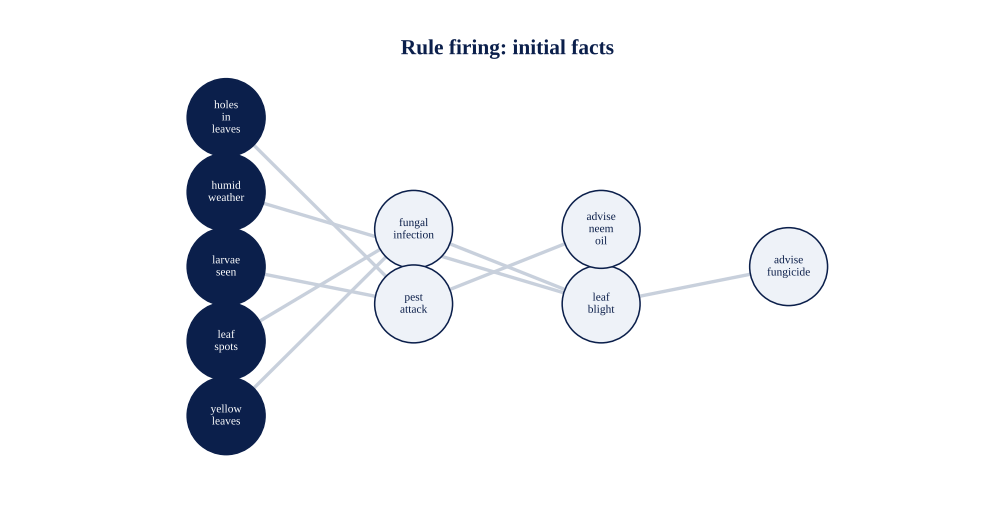

In [3]:
import networkx as nx
G = nx.DiGraph()
for rid, prem, c, cf in trace:
    for p in prem: G.add_edge(p, c, label=rid)
layers = {}
def depth(n): return 0 if n in case else 1 + max(depth(p) for p in G.predecessors(n))
for n in G.nodes: layers.setdefault(depth(n), []).append(n)
pos = {n: (d * 3.0, -i * 1.2 + len(ns) * 0.6) for d, ns in layers.items() for i, n in enumerate(sorted(ns))}
order = [rid for rid, *_ in trace]
fig, ax = plt.subplots(figsize=(9, 4.8))
def fr(k):
    ax.clear(); fired = set(order[:k]); lit = set(case) | {c for rid, _, c, _ in trace if rid in fired}
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color=[GOLD if G[u][v]["label"] in fired else "#C8D0DC" for u, v in G.edges], width=2.2, arrowsize=14)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=[(LEAF if n.startswith("advise") else NAVY) if n in lit else MIST for n in G.nodes], node_size=2600, edgecolors=NAVY)
    for group, fc in ((lit, "white"), (set(G.nodes) - lit, NAVY)):
        nx.draw_networkx_labels(G, pos, ax=ax, labels={n: n.replace("_", "\n") for n in G.nodes if n in group}, font_size=7.5,
                                font_family="serif", font_color=fc)
    ax.set_title(f"Rule firing: {', '.join(order[:k]) or 'initial facts'}"); ax.axis("off"); ax.margins(0.12)
gif = save_gif(animation.FuncAnimation(fig, fr, frames=len(order) + 3), "exp10_expert_system_firing.gif", fps=1)
display(Image(filename=gif))

### Basic admission chatbot (pattern / keyword matching)

In [4]:
import re
INTENTS = [
 ("greet",    r"\b(hi|hello|hey|namaste)\b",                 "Hello! I am the Sanjivani AI&DS admission assistant. How can I help?"),
 ("fees",     r"\b(fee|fees|cost|tuition)\b",                "Fee details for B.Tech AI & DS are on the university admissions portal; scholarships are available for eligible students."),
 ("eligible", r"\b(eligib\w*|criteria|qualify|jee|mht.?cet)\b", "Eligibility: 10+2 with Physics & Mathematics and a valid MHT-CET / JEE Main score."),
 ("courses",  r"\b(course|subject|syllabus|curriculum)\b",   "The curriculum covers AI, ML, Deep Learning, Data Engineering and an industry internship."),
 ("hostel",   r"\b(hostel|accommodation|stay)\b",            "Separate hostels for boys and girls are available on campus."),
 ("placement",r"\b(placement\w*|jobs?|package|recruit\w*)\b",     "The Training & Placement cell runs aptitude training and campus drives every year."),
 ("contact",  r"\b(contact|phone|email|address)\b",          "Please visit the university website or the admissions office, Kopargaon."),
 ("bye",      r"\b(bye|thanks|thank you)\b",                 "Thank you! All the best for your admission."),
]
def reply(msg):
    m = msg.lower()
    for name, pat, ans in INTENTS:
        if re.search(pat, m): return name, ans
    return "fallback", "Sorry, I did not understand. You can ask about fees, eligibility, courses, hostel or placements."
for q in ["Hi there!", "What is the eligibility for AI and DS?", "How much are the fees?", "Is hostel available?",
          "Tell me about placements", "Can I study astrophysics?", "Thanks, bye"]:
    intent, ans = reply(q); print(f"👤 {q}\n🤖 [{intent}] {ans}\n")

👤 Hi there!
🤖 [greet] Hello! I am the Sanjivani AI&DS admission assistant. How can I help?

👤 What is the eligibility for AI and DS?
🤖 [eligible] Eligibility: 10+2 with Physics & Mathematics and a valid MHT-CET / JEE Main score.

👤 How much are the fees?
🤖 [fees] Fee details for B.Tech AI & DS are on the university admissions portal; scholarships are available for eligible students.

👤 Is hostel available?
🤖 [hostel] Separate hostels for boys and girls are available on campus.

👤 Tell me about placements
🤖 [placement] The Training & Placement cell runs aptitude training and campus drives every year.

👤 Can I study astrophysics?
🤖 [fallback] Sorry, I did not understand. You can ask about fees, eligibility, courses, hostel or placements.

👤 Thanks, bye
🤖 [bye] Thank you! All the best for your admission.



In [5]:
tests = [("hello", "greet"), ("fees structure?", "fees"), ("am I eligible with JEE", "eligible"), ("syllabus please", "courses"),
         ("where do I stay", "hostel"), ("average package", "placement"), ("email id", "contact"), ("thank you", "bye"), ("weather today", "fallback")]
acc = np.mean([reply(q)[0] == t for q, t in tests]); print(f"Intent accuracy on test prompts: {acc:.0%}")

Intent accuracy on test prompts: 100%


## ✅ Result and Conclusion

<div style="border-left:6px solid #2E7D32;background:#E3F2E4;padding:12px 18px;border-radius:6px;font-family:'Times New Roman',serif;color:#1A202C">
<b style="color:#2E7D32">Conclusion</b><br>The expert system chained symptom rules to diagnoses and advice, combined certainty factors and explained its reasoning; the chatbot correctly mapped all test prompts to intents, falling back gracefully for unknown queries.</div>

## 🎤 Viva Questions

1. List the components of an expert system.
2. How are certainty factors combined in MYCIN?
3. What is conflict resolution in a production system?
4. What is the role of the explanation facility?
5. How would you improve the chatbot using machine learning?